In [6]:
import pandas as pd
df = pd.read_csv("Boyce_etal_2022_NATCC.csv")

In [3]:
#Data Exploration 
print(df.head(5))
print(df.tail(5))
print(df.columns.tolist())
print(df.shape)

   Unnamed: 0 Experiment                                    SpecID  \
0           1     SSP126                                Brc-378165   
1           2     SSP126  Chn-013ca97e-46a8-4c5e-b398-8bb4f340f88b   
2           3     SSP126  Chn-015453c0-3ff9-477d-ab51-c68d85e65af5   
3           4     SSP126  Chn-0e470b93-1bf9-4c28-8770-166bb5e2a8c7   
4           5     SSP126  Chn-0e9cfa5e-eab6-490e-9279-34eeeb127eb2   

                 SPname   Kingdom      Phylum              Family  \
0  Lightiella floridana  Animalia  Arthropoda  Hutchinsoniellidae   
1      Lenisquilla lata  Animalia  Arthropoda          Squillidae   
2    Clorida albolitura  Animalia  Arthropoda          Squillidae   
3   Levisquilla jurichi  Animalia  Arthropoda          Squillidae   
4  Lophosquilla tiwarii  Animalia  Arthropoda          Squillidae   

                   Comname  ClimSens  ClimSensSD  ...  ClimExpoSD  ClimAdapt  \
0                      NaN  0.594191    0.036207  ...    0.060402   0.390361   
1  M

In [ ]:
#Problem Defintion: What is the effect of Climate change on the the region of animal and affact on animal it self

In [3]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 49950 entries, 0 to 49949
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     49950 non-null  int64  
 1   Experiment     49950 non-null  str    
 2   SpecID         49950 non-null  str    
 3   SPname         49950 non-null  str    
 4   Kingdom        49950 non-null  str    
 5   Phylum         49950 non-null  str    
 6   Family         49950 non-null  str    
 7   Comname        28776 non-null  str    
 8   ClimSens       49950 non-null  float64
 9   ClimSensSD     49908 non-null  float64
 10  ClimExpo       49950 non-null  float64
 11  ClimExpoSD     49908 non-null  float64
 12  ClimAdapt      49950 non-null  float64
 13  ClimAdaptSD    49908 non-null  float64
 14  ClimVuln       49950 non-null  float64
 15  ClimVulnSD     49950 non-null  float64
 16  ClimSensRisk   49950 non-null  str    
 17  ClimExpoRisk   49950 non-null  str    
 18  ClimAdaptRisk  49

In [4]:
#Data Cleaning
#check for updated column names
print(df.head())

   Unnamed: 0 Experiment                                    SpecID  \
0           1     SSP126                                Brc-378165   
1           2     SSP126  Chn-013ca97e-46a8-4c5e-b398-8bb4f340f88b   
2           3     SSP126  Chn-015453c0-3ff9-477d-ab51-c68d85e65af5   
3           4     SSP126  Chn-0e470b93-1bf9-4c28-8770-166bb5e2a8c7   
4           5     SSP126  Chn-0e9cfa5e-eab6-490e-9279-34eeeb127eb2   

                 SPname   Kingdom      Phylum              Family  \
0  Lightiella floridana  Animalia  Arthropoda  Hutchinsoniellidae   
1      Lenisquilla lata  Animalia  Arthropoda          Squillidae   
2    Clorida albolitura  Animalia  Arthropoda          Squillidae   
3   Levisquilla jurichi  Animalia  Arthropoda          Squillidae   
4  Lophosquilla tiwarii  Animalia  Arthropoda          Squillidae   

                   Comname  ClimSens  ClimSensSD  ...  ClimExpoSD  ClimAdapt  \
0                      NaN  0.594191    0.036207  ...    0.060402   0.390361   
1  M

In [5]:
#Check for missing values
print(df.isnull().sum())
# Check the percentage of missing values
print((df.isnull().sum() / len(df)) * 100)
# Drop Comname because it has a high percentage of missing values (not important for analysis)
df = df.drop(columns=['Comname'])
#Verify that Comname was dropped
print(df.columns)

Unnamed: 0           0
Experiment           0
SpecID               0
SPname               0
Kingdom              0
Phylum               0
Family               0
Comname          21174
ClimSens             0
ClimSensSD          42
ClimExpo             0
ClimExpoSD          42
ClimAdapt            0
ClimAdaptSD         42
ClimVuln             0
ClimVulnSD           0
ClimSensRisk         0
ClimExpoRisk         0
ClimAdaptRisk        0
ClimRisk             0
Ncells               0
dtype: int64
Unnamed: 0        0.000000
Experiment        0.000000
SpecID            0.000000
SPname            0.000000
Kingdom           0.000000
Phylum            0.000000
Family            0.000000
Comname          42.390390
ClimSens          0.000000
ClimSensSD        0.084084
ClimExpo          0.000000
ClimExpoSD        0.084084
ClimAdapt         0.000000
ClimAdaptSD       0.084084
ClimVuln          0.000000
ClimVulnSD        0.000000
ClimSensRisk      0.000000
ClimExpoRisk      0.000000
ClimAdaptRisk     

In [6]:
#Check for duplicates
print("Number of duplicates:", df.duplicated().sum())
#there is no duplicates in the dataset

Number of duplicates: 0


In [4]:
#Rename columns
df = df.rename(columns={
    'Experiment': 'Climate_Scenario',
    'SpecID': 'Species_ID',
    'SPname': 'Species_Name',
    'ClimSens': 'Climate_Sensitivity',
    'ClimSensSD': 'Sensitivity_SD',
    'ClimExpo': 'Climate_Exposure',
    'ClimExpoSD': 'Exposure_SD',
    'ClimAdapt': 'Climate_Adaptation',
    'ClimAdaptSD': 'Adaptation_SD',
    'ClimVuln': 'Climate_Vulnerability',
    'ClimVulnSD': 'Vulnerability_SD',
    'ClimSensRisk': 'Sensitivity_Risk_Level',
    'ClimExpoRisk': 'Exposure_Risk_Level',
    'ClimAdaptRisk': 'Adaptation_Risk_Level',
    'ClimRisk': 'Overall_Climate_Risk'
    })


In [9]:

#Descriptive statistics for numerical columns
print("The mean climate sensitivity is:", df['Climate_Sensitivity'].mean()) #avg
print("The mean climate vulnerability is:", df['Climate_Vulnerability'].mean())

print("The median climate sensitivity is:", df['Climate_Sensitivity'].median())#middle value
print("The median climate vulnerability is:", df['Climate_Vulnerability'].median())

#Spread of climate sensitivity to understand the average sensitivity, the spread of values,
# and the differences in sensitivity across species.


The mean climate sensitivity is: 0.47737841565236944
The mean climate vulnerability is: 0.4872187791906317
The median climate sensitivity is: 0.4819876
The median climate vulnerability is: 0.48520465


In [10]:
max_value = df['Climate_Sensitivity'].max()
min_value = df['Climate_Sensitivity'].min()
range_value = max_value - min_value
print("Maximum climate sensitivity: {} \n Minimum climate sensitivity: {} \n Range: {}".format(max_value, min_value, range_value))
print("Standard deviation of climate sensitivity:", df['Climate_Sensitivity'].std())

Maximum climate sensitivity: 0.8766647 
 Minimum climate sensitivity: 0.1304241 
 Range: 0.7462405999999999
Standard deviation of climate sensitivity: 0.08253890463918406


In [11]:
# IQR
sens = df['Climate_Sensitivity']
q1, q3 = sens.quantile(0.25), sens.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [12]:
outliers = df[(sens < lower) | (sens > upper)]
print(f"Q1: {q1:.3f} | Q3: {q3:.3f} | IQR: {iqr:.3f}")
print(f"Lower bound: {lower:.3f} | Upper bound: {upper:.3f}")
print(f"Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")

Q1: 0.438 | Q3: 0.521 | IQR: 0.082
Lower bound: 0.315 | Upper bound: 0.644
Number of outliers: 3192 (6.4%)


In [5]:
# IQR
sens = df['Climate_Exposure']
q1, q3 = sens.quantile(0.25), sens.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [ ]:
outliers = df[(sens < lower) | (sens > upper)]
print(f"Q1: {q1:.3f} | Q3: {q3:.3f} | IQR: {iqr:.3f}")
print(f"Lower bound: {lower:.3f} | Upper bound: {upper:.3f}")
print(f"Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")

#there is no outlier in Expouse 

Q1: 0.186 | Q3: 0.526 | IQR: 0.340
Lower bound: -0.324 | Upper bound: 1.036
Number of outliers: 0 (0.0%)


In [ ]:

print("Kingdoms Number:", df['Kingdom'].nunique())
print("Families Number:", df['Family'].nunique())
print("Phylumes Number:",df['Phylum'].nunique())
print("Species Number:", df['Species_Name'].nunique())


Kingdoms Number: 5
Families Number: 1766
Phylumes Number: 40
Species Number: 24975


<Axes: title={'center': ' Kingdoms by Count'}, xlabel='Kingdom'>

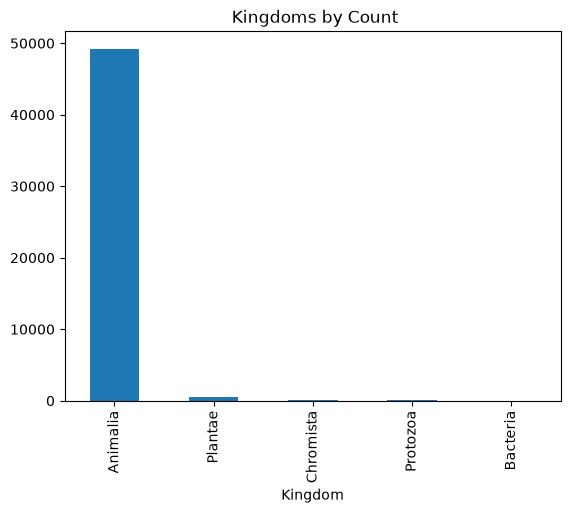

In [ ]:
#let's take look of the data that we have:
df['Kingdom'].value_counts().plot(kind='bar', title=' Kingdoms by Count')    
# imbalance class the most kingdoms it : Animalia 
#هذا معناته انه المتوسط بينحاز الى المملكه االاكثر عدد 

<Axes: title={'center': 'Top 10 Species by Count'}, xlabel='Species_Name'>

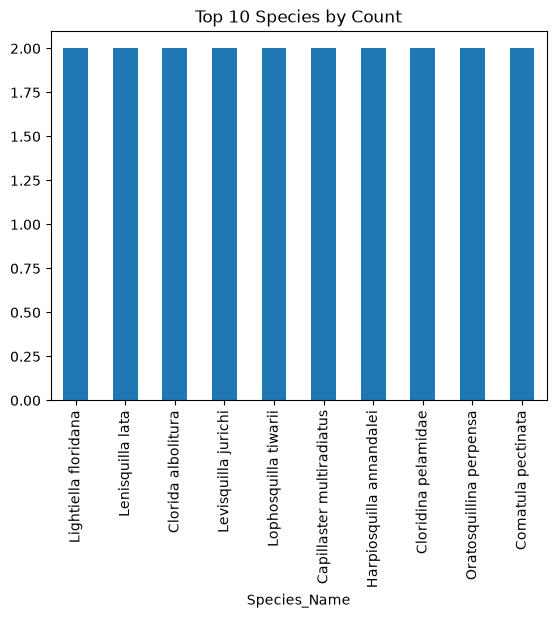

In [ ]:
df['Species_Name'].value_counts().head(10).plot(kind='bar', title='Top 10 Species by Count')  
# كل كائن يظهر مرتين بالضبط (مرة لكل سيناريو مناخي: SSP126 وSSP585)،
# لذلك فرسمة الأعداد لا تميّز بين الكائنات وإنما تعكس بنية البيانات فقط.

<Axes: title={'center': 'Top 10 Family by Count'}, xlabel='Phylum'>

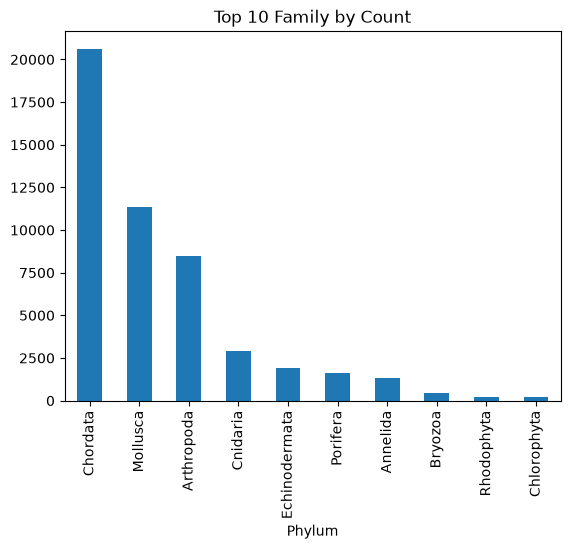

In [ ]:
df['Phylum'].value_counts().head(10).plot(kind='bar', title='Top 10 Phylum by Count')  
# Chordata is the most represented phylum, with over 20,000 records (each species appears twice, once per climate scenario)

In [9]:
df.groupby(['Kingdom', 'Climate_Scenario']).size().unstack()

# الهشاشة المناخية أعلى تحت سيناريو الانبعاثات العالية (SSP585) في جميع الممالك الخمس،
# بوسيط حوالي 0.51 مقابل حوالي 0.45 تحت SSP126، والفرق بين السيناريوهين أوضح من الفرق بين الممالك.
# الحيوانات (Animalia) تشكل الغالبية العظمى من البيانات، ولذلك تظهر فيها قيم شاذة كثيرة على الجهتين.
# مملكة Bacteria ممثلة بـ 8 صفوف فقط (حوالي 4 كائنات، كل كائن تحت سيناريوهين)،
# فصندوقها الضيق يعكس صغر العينة وليس ثباتاً فعلياً، ولا يصلح مقارنتها بباقي الممالك.

Climate_Scenario,SSP126,SSP585
Kingdom,,
Animalia,24617,24617
Bacteria,8,8
Chromista,72,72
Plantae,230,230
Protozoa,48,48


In [ ]:
#since that we know that the most kingdom is Animalia
#how is the most Species_Name affect with climate change?
animals = df[df['Kingdom'] == 'Animalia']
cols = ['Species_Name', 'Climate_Vulnerability', 'Climate_Sensitivity', 'Climate_Exposure', 'Climate_Adaptation']
animals[animals['Climate_Scenario']=='SSP585'].nlargest(5, 'Climate_Vulnerability')[cols]

# أعلى 5 حيوانات هشاشة تحت سيناريو الانبعاثات العالية (SSP585).
# الهشاشة هي النتيجة النهائية التي تجمع الحساسية والتعرض والتكيف.
# هذه الأنواع تتميز بهشاشة عالية (حوالي 0.74 إلى 0.76) نتيجة تعرض مرتفع وحساسية مرتفعة في الغالب،
# مع قدرة تكيف منخفضة في أغلبها.
# القيم متقاربة بين الأنواع، فالفروق في الترتيب بينها صغيرة.



,Species_Name,Climate_Vulnerability,Climate_Sensitivity,Climate_Exposure,Climate_Adaptation
49228,Cladocora caespitosa,0.756523,0.848685,0.686994,0.413387
33003,Azurina eupalama,0.749029,0.773053,0.737921,0.270340
37708,Petrolisthes extremus,0.744698,0.592774,0.616520,0.193160
31064,Takifugu chinensis,0.742594,0.876665,0.589007,0.543171
28092,Maculabatis arabica,0.738992,0.826543,0.614811,0.328899


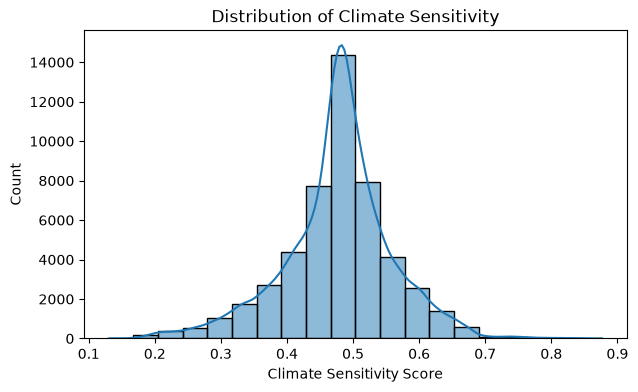

In [ ]:
#Distribution of Climate Sensitivity (Univariate Analysis)
#Histogram to visualize the distribution of Climate Sensitivity
#الى أي درجه يتاثر الحيوان بالتغيرات المناخيه ؟ - 
# #The effact of the Animal it self
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="Climate_Sensitivity", bins=20, kde=True)
plt.title("Distribution of Climate Sensitivity")
plt.xlabel("Climate Sensitivity Score")
plt.ylabel("Count")
plt.show()
# توزيع حساسية الكائنات (24,975 كائن فريد) قريب من الشكل الجرسي، ومتوسطه 0.48 ووسيطه 0.48 تقريباً.
# نصف الكائنات تقع حساسيتها بين 0.44 و0.52، يعني أن أغلبها تتركز حول 0.5 مع انحراف معياري صغير (0.08).
# تمتد القيم من 0.13 إلى 0.88، فيه كائنات قليلة جداً ذات حساسية منخفضة أو عالية جداً.

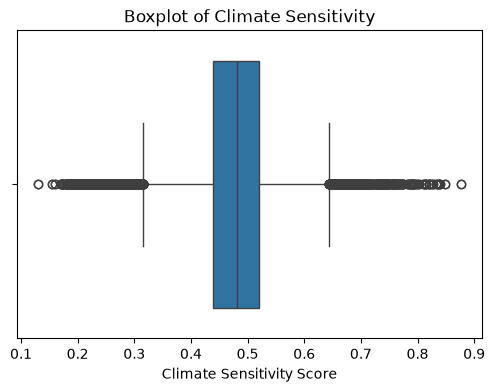

In [ ]:
# Boxplot to detect outliers in Climate Sensitivity
import matplotlib.pyplot as plt
import seaborn as sns
#مدى انتشار بيانات تاثر الحيوانات بالتغيير المناخي؟-
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="Climate_Sensitivity")
plt.title("Boxplot of Climate Sensitivity")
plt.xlabel("Climate Sensitivity Score")
plt.show()

#اضفت هذه الرسمه وهي اوضح لتاثير التغيير المناخي على الحيوان  وتوضح القيم الشاذه بشكل اوضح 

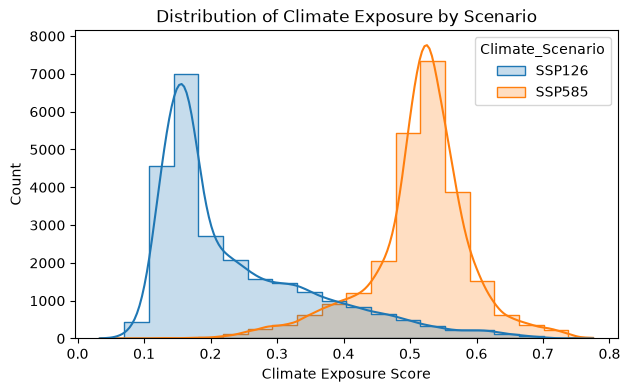

In [ ]:
#The effact of the animal place depend on two scenrio : 
plt.figure(figsize=(7,4))
sns.histplot(data=df, x="Climate_Exposure", hue="Climate_Scenario",
             bins=20, kde=True, element="step")
plt.title("Distribution of Climate Exposure by Scenario")
plt.xlabel("Climate Exposure Score")
plt.ylabel("Count")
plt.show()
#الى أي درجه يتاثر مناطق الحيوان بالتغيرات المناخيه ؟ - 
#تعرض مناطق الحيوانات على حسب السيناريو
#هنا الانبعاثات الاعلى 585 score التعرض اعلى 
#معناته انه كل ما ارتفعت الانبعاثات زاد التاثير على مناطق هذه الكائنات 
#ولما حسبنا المتوسط طلع معناالفرق بينهم 0.23-0.51=0.28


# يظهر ارتفاع في التعرض حتى تحت سيناريو الانبعاثات القليلة (SSP126).
# ويُفسَّر ذلك على الأرجح بتأخر استجابة المناخ: الغازات التي انبعثت في الماضي تبقى في الجو وتستمر في تسخين المحيطات،
# فيستمر التغير المناخي وتتأثر الكائنات حتى مع انخفاض الانبعاثات.

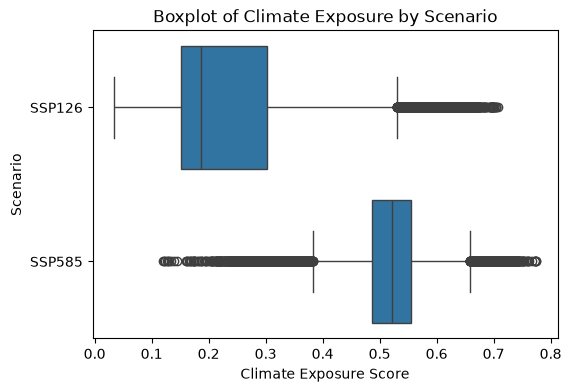

In [ ]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="Climate_Exposure", y="Climate_Scenario")
plt.title("Boxplot of Climate Exposure by Scenario")
plt.xlabel("Climate Exposure Score")
plt.ylabel("Scenario")
plt.show()

#مدى انتشار البيانات في منطقه الحيوان Exposure ؟

# كلا السيناريوهين يظهر فيهما تعرض لمناطق الكائنات، لكن قيم التعرض أعلى بوضوح تحت SSP585 (الوسيط حول 0.52 مقابل حول 0.19 في SSP126).
# SSP126 فيه قيم شاذة على اليمين فقط (كائنات تعرضها أعلى من المعتاد)، بينما SSP585 فيه قيم شاذة على الجهتين،
# وأكثرها على اليسار (كائنات تعرضها أقل من المعتاد حتى مع الانبعاثات العالية).



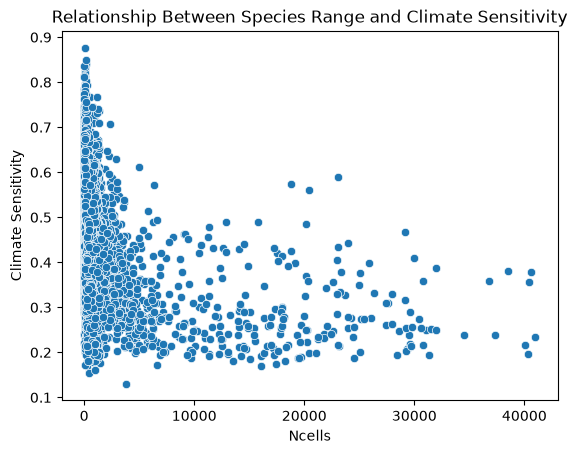

In [ ]:
#Bivariate Analysis:
#N vs N Ncell and Climate Sensitivity

sns.scatterplot(data=df, x='Ncells', y='Climate_Sensitivity')
plt.xlabel('Ncells')
plt.ylabel('Climate Sensitivity')
plt.title('Relationship Between Species Range and Climate Sensitivity')
plt.show()

#هل الكائنات ذات النطاق الصغير أكثر حساسية؟
# الكائنات اللي منطقتها صغيرة (Ncells قليل) تميل لحساسية مناخية أعلى
# بينما الكائنات المنتشرة في مناطق واسعة حساسيتها غالباً منخفضة إلى متوسطة




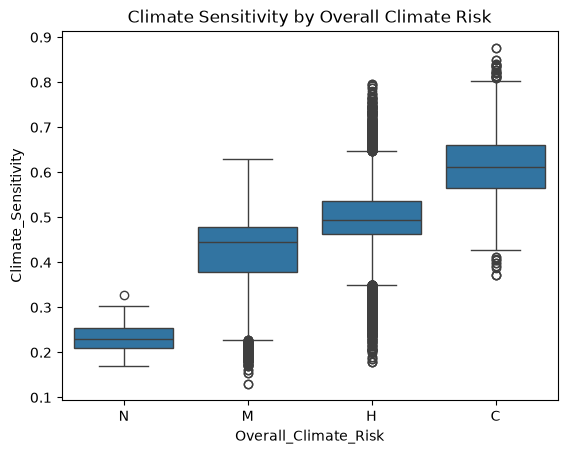

In [ ]:
#N vs C 
#هل الأنواع التي تواجه تغيرًا مناخيًا أشد (تعرّض أعلى) تقع في فئات خطر أعلى؟
#Overall_Climate_Risk  --Sensitivity_Risk_Level،  VS Climate_Sensitivity  
order = ['N', 'M', 'H', 'C']
sns.boxplot(data=df, x='Overall_Climate_Risk', y='Climate_Sensitivity', order=order)
plt.title('Climate Sensitivity by Overall Climate Risk')
plt.show()

# كلما ارتفعت فئة الخطر الكلي 
# (N < M < H < C) ارتفعت حساسية الكائنات للتغير المناخي
# من متوسط 0.23 في N إلى 0.61 في C
# وترتفع معها قيم التعرض وتنخفض قدرة التكيف، فالخطر العالي ينتج من اجتماع هذه العوامل الثلاثة



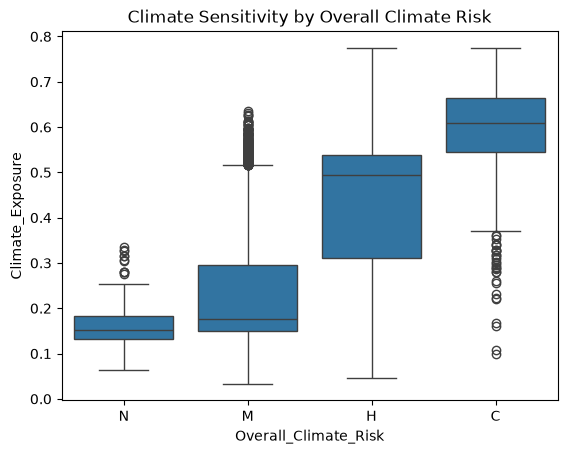

In [ ]:
#N vs C 
#هل المناطق التي تواجه تغيرًا مناخيًا أشد (تعرّض أعلى) تقع في فئات خطر أعلى؟
#Overall_Climate_Risk  --Sensitivity_Risk_Level،  VS Climate_Exposure  
order = ['N', 'M', 'H', 'C']
sns.boxplot(data=df, x='Overall_Climate_Risk', y='Climate_Exposure', order=order)
plt.title('Climate Sensitivity by Overall Climate Risk')
plt.show()



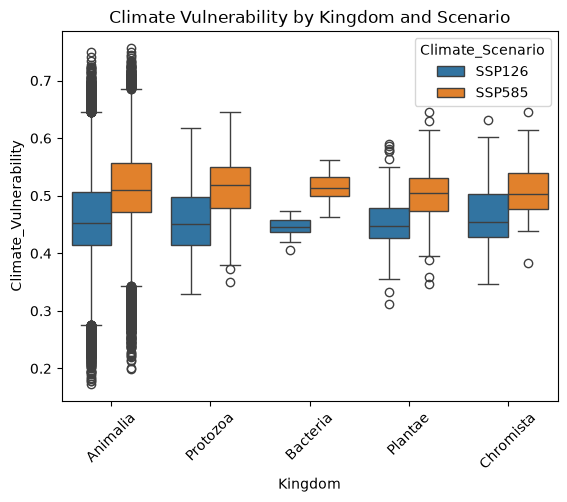

In [ ]:
sns.boxplot(data=df, x='Kingdom', y='Climate_Vulnerability', hue='Climate_Scenario')
plt.title('Climate Vulnerability by Kingdom and Scenario')
plt.xticks(rotation=45)
plt.show()

# Does climate vulnerability differ across kingdoms, and does the climate scenario change it? 
#Yes its change , as you can see that at all the kingdoms vulnerabilty was higher at SS585 - Negtavie affact- (higher climate )

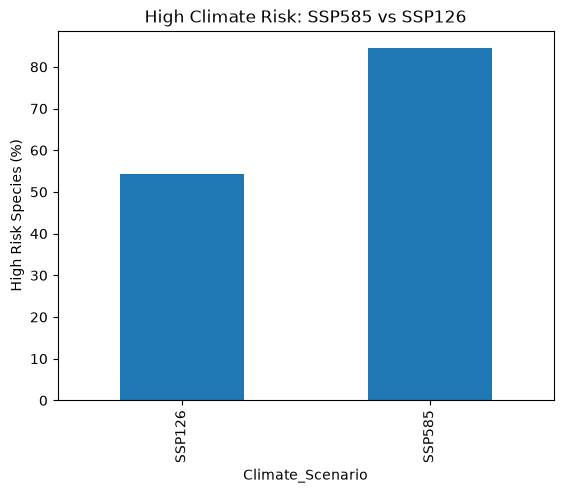

In [ ]:
#multivariate analysis of Kingdom,Family,SPname 


#هل تزيد نسبة الأنواع ذات الخطر المناخي العالي
#(H) في سيناريو الانبعاثات الأعلى (SSP585) مقارنة بسيناريو الانبعاثات الأقل (SSP126)؟
risk = df[df['Overall_Climate_Risk'] == 'H']
percentage = risk.groupby('Climate_Scenario').size() / \
             df.groupby('Climate_Scenario').size() * 100
percentage.plot(kind='bar')
plt.ylabel('High Risk Species (%)')
plt.title('High Climate Risk: SSP585 vs SSP126')
plt.show()


# نسبة الأنواع المصنّفة ضمن فئة الخطر H ترتفع من حوالي 54% تحت SSP126 إلى حوالي 84% تحت SSP585،
# أي أن نسبة أكبر بكثير من الأنواع تقع في فئة الخطر العالي عند ارتفاع الانبعاثات.
# هذه النسبة تخص فئة H فقط، ولا تشمل الفئة الأعلى C.



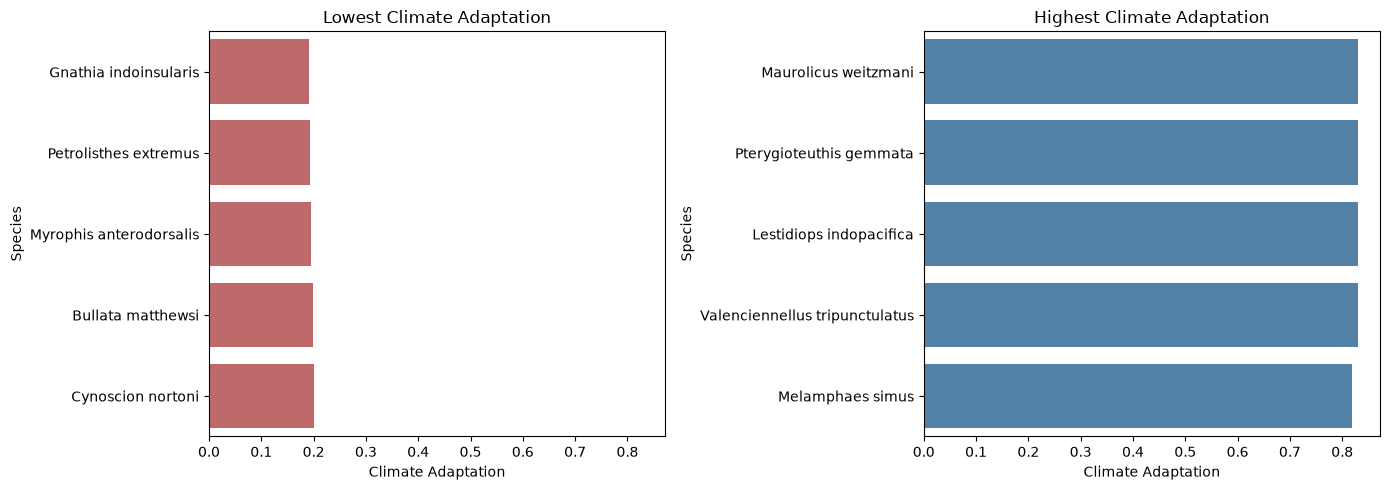

In [ ]:
#ما الأنواع التي تملك أقل قدرة/اعلى قدره على التكيّف مع التغير المناخي؟
#N Vs C Climate Adaptation vs Climate Sensitivity
unique = df.drop_duplicates('Species_ID')

low = unique.nsmallest(5, 'Climate_Adaptation')
high = unique.nlargest(5, 'Climate_Adaptation')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.barplot(data=low, x='Climate_Adaptation', y='Species_Name', color='indianred', ax=axes[0])
axes[0].set_title('Lowest Climate Adaptation')

sns.barplot(data=high, x='Climate_Adaptation', y='Species_Name', color='steelblue', ax=axes[1])
axes[1].set_title('Highest Climate Adaptation')

for ax in axes:
    ax.set_xlabel('Climate Adaptation')
    ax.set_ylabel('Species')
plt.tight_layout()
plt.show()


# أقل الأنواع قدرة على التكيف تتراوح قيمها حول 0.19 إلى 0.2
# بينما أعلاها تصل إلى حوالي 0.8، بفرق حوالي 0.6 نقطة (حوالي 4 أضعاف)
# القيم المنخفضة تعني ضعف القدرة على التكيف مع التغير المناخي، وهي مؤشر سلبي للكائن.
# هذه المقارنة بين الأطراف فقط ولا تمثل التوزيع العام للتكيف



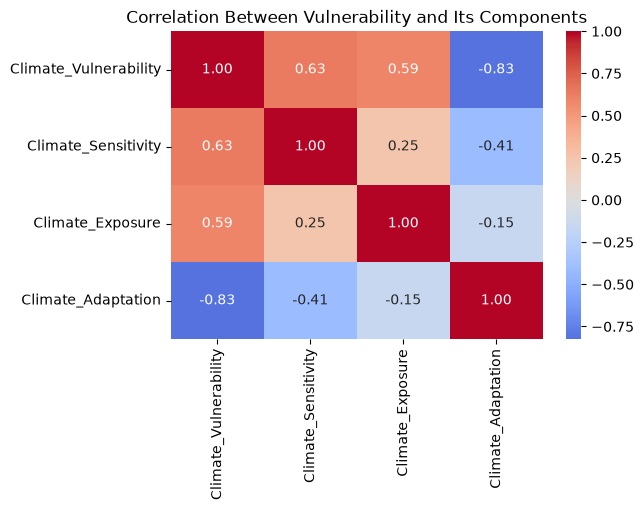

In [94]:
#multivriate analysis
# العلاقة بين الهشاشة المناخية ومكوّناتها (Correlation Analysis)
corr = df[['Climate_Vulnerability','Climate_Sensitivity','Climate_Exposure','Climate_Adaptation']].corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Between Vulnerability and Its Components')
plt.show()

# ترتبط الهشاشة المناخية موجباً بالحساسية (0.63) والتعرض (0.59)، وسالباً بالتكيف (-0.83).
# التكيف هو الأقوى ارتباطاً بالهشاشة، أي كل ما قلّت قدرة الكائن على التكيف ارتفعت هشاشته غالباً.
# الارتباط بين المكوّنات نفسها ضعيف إلى متوسط (0.25 بين الحساسية والتعرض)، فكل مكوّن يضيف معلومة مختلفة.
# هذا ارتباط وليس سببية، ولا يحدد الصيغة التي حُسبت بها الهشاشة.

SSP1 2.6 (SSP126) describes a sustainable, low emissions future in which societies adopt environmentally friendly development pathways, resulting in one of the lowest warming outcomes among the SSP scenarios.

SSP585 represents a future with minimal climate action, high fossil fuel use, and severe warming, serving as a critical tool for understanding potential climate risks and testing the resilience of mitigation and adaptation strategies.


-----------------------------
Sensitivity: how much the species itself is affected
Exposure: how much climate change hits its habitat
Adaptation: its ability to cope (higher = better)
Vulnerability: the combined result
Risk levels: N (none) < M (moderate) < H (high) < C (critical) | Ncells: number of grid cells the species occupies (range size)